# House Price Prediction: Reproducible Model Audit

## tl;dr

The original neural network had a test R² of about **-2.64**, contained a credit-score filtering bug, leaked preprocessing information across the train/test boundary, and ended with an invalid prediction call.

After correcting the workflow, the best cross-validated candidate is a **median baseline**, with holdout **R² = -0.002**, **MAE = 66,651**, and **RMSE = 91,310** target units. The supplied features do not contain useful predictive signal for this target. The repository therefore saves the honest baseline artifact and should be treated as a learning project, not a production pricing system.

## Context & Methods

This notebook audits a 1,200-row regression dataset and compares lightweight models using a leakage-safe scikit-learn pipeline.

### Key Assumptions

- `target_house_price` is the regression target.
- `?` in `city_index` represents an unknown value and is converted to missing.
- Extreme target values are retained because no domain rule or source documentation proves they are errors.
- Model selection uses five-fold cross-validation only on the training partition; the holdout set is evaluated once.
- R², MAE, and RMSE—not classification accuracy—are appropriate evaluation metrics.

In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.train import (
    DEFAULT_MODEL_DIR,
    RANDOM_STATE,
    TEST_SIZE,
    evaluate_candidates,
    load_dataset,
    regression_metrics,
    split_features_target,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
DATA_PATH = PROJECT_ROOT / "data" / "unclean_regression_dataset.csv"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## Data

### 1. Load and validate the repository dataset

In [2]:
data = load_dataset(DATA_PATH)
X, y = split_features_target(data)

print(f"Rows: {len(data):,}")
print(f"Input features: {X.shape[1]}")
display(data.head())

Rows: 1,200
Input features: 9


,age,income,experience_years,education_level,hours_per_week,city_index,credit_score,loan_amount,debt_ratio,target_house_price
0,56,97482.834868,28,phd,67,A,603.916766,20577.477285,0.434247,170008.376620
1,69,NaN,8,NaN,39,A,612.657030,-15824.386761,0.996189,425488.209249
2,46,37469.516346,37,master,58,D,650.388062,37698.701156,0.639888,115528.393380
3,32,6157.398875,5,highschool,79,D,812.217492,51050.395737,1.333679,210012.832208
4,60,67028.041848,18,master,21,NaN,NaN,39260.615103,1.267838,272379.840056


### 2. Audit missingness, duplicates, and the target

In [3]:
audit = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "missing_count": data.isna().sum(),
    "missing_percent": data.isna().mean().mul(100).round(1),
    "unique_values": data.nunique(dropna=True),
})

print(f"Duplicate rows: {data.duplicated().sum():,}")
display(audit)
display(y.describe().to_frame(name="target_house_price"))

Duplicate rows: 0


,dtype,missing_count,missing_percent,unique_values
age,int64,0,0.0,62
income,float64,120,10.0,1080
experience_years,int64,0,0.0,40
education_level,object,250,20.8,4
hours_per_week,int64,0,0.0,60
city_index,object,248,20.7,4
credit_score,float64,120,10.0,1080
loan_amount,float64,120,10.0,1080
debt_ratio,float64,0,0.0,1200
target_house_price,float64,0,0.0,1200


,target_house_price
count,1.200000e+03
mean,2.669841e+05
std,1.475130e+05
min,-1.313163e+03
25%,1.960520e+05
50%,2.536210e+05
75%,3.108752e+05
max,1.791667e+06


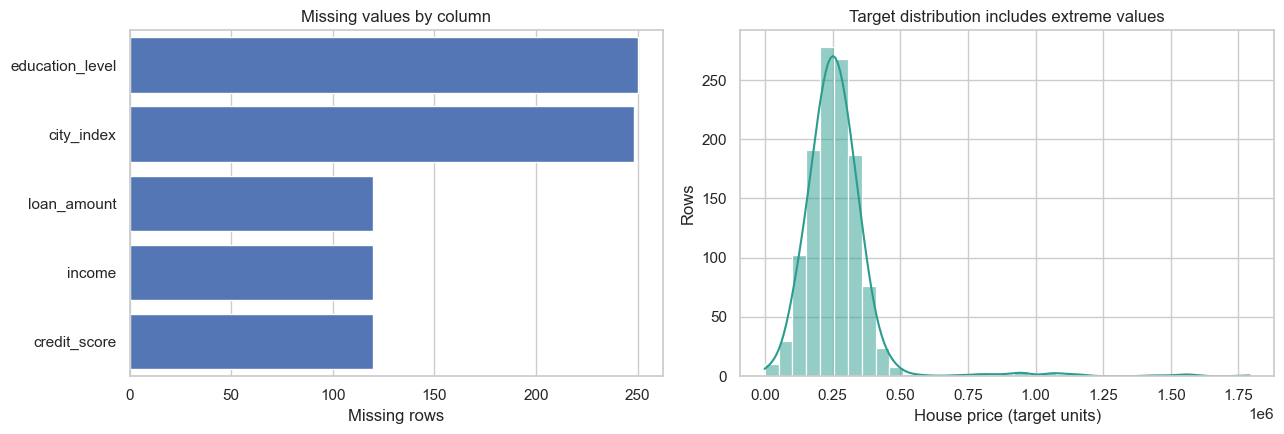

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

missing = data.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
sns.barplot(x=missing.values, y=missing.index, color="#4472C4", ax=axes[0])
axes[0].set_title("Missing values by column")
axes[0].set_xlabel("Missing rows")
axes[0].set_ylabel("")

sns.histplot(y, bins=35, kde=True, color="#2A9D8F", ax=axes[1])
axes[1].set_title("Target distribution includes extreme values")
axes[1].set_xlabel("House price (target units)")
axes[1].set_ylabel("Rows")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "data_quality_overview.png", dpi=160, bbox_inches="tight")
plt.show()

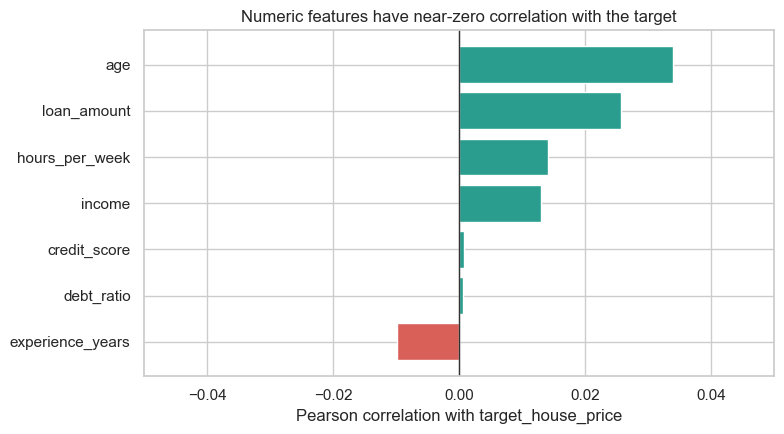

,correlation
experience_years,-0.009864
debt_ratio,0.000653
credit_score,0.000855
income,0.013095
hours_per_week,0.014078
loan_amount,0.025732
age,0.034039


In [5]:
numeric_correlations = (
    data.corr(numeric_only=True)["target_house_price"]
    .drop("target_house_price")
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#D95F59" if value < 0 else "#2A9D8F" for value in numeric_correlations]
ax.barh(numeric_correlations.index, numeric_correlations.values, color=colors)
ax.axvline(0, color="#333333", linewidth=1)
ax.set_title("Numeric features have near-zero correlation with the target")
ax.set_xlabel("Pearson correlation with target_house_price")
ax.set_ylabel("")
ax.set_xlim(-0.05, 0.05)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "feature_target_correlations.png", dpi=160, bbox_inches="tight")
plt.show()

display(numeric_correlations.to_frame("correlation"))

The missing values are handled inside the model pipeline. The target has a long upper tail and even a negative value, but removing rows solely because the label is surprising would require documented domain rules. The near-zero feature/target correlations are an early warning that a useful predictive model may not be possible with these inputs.

## Results

### 3. Create an untouched holdout set

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

print(f"Training rows: {len(X_train):,}")
print(f"Holdout rows: {len(X_test):,}")

Training rows: 960
Holdout rows: 240


### 4. Compare candidates with five-fold cross-validation

In [7]:
cv_results, pipeline_templates = evaluate_candidates(X_train, y_train)

formatted_cv = cv_results.copy()
formatted_cv["cv_r2_mean"] = formatted_cv["cv_r2_mean"].round(4)
formatted_cv["cv_r2_std"] = formatted_cv["cv_r2_std"].round(4)
formatted_cv["cv_mae"] = formatted_cv["cv_mae"].round(0).astype(int)
formatted_cv["cv_rmse"] = formatted_cv["cv_rmse"].round(0).astype(int)
display(formatted_cv)

,model,cv_r2_mean,cv_r2_std,cv_mae,cv_rmse
0,Dummy median baseline,-0.0128,0.0090,84636,153585
1,ElasticNet,-0.0207,0.0228,86826,153723
2,Gradient boosting,-0.0390,0.0178,86786,155272
3,Ridge,-0.0496,0.0374,88919,155632


A negative cross-validated R² means a candidate is worse than predicting the validation fold's mean. None of the feature-based candidates beats the simple median baseline, so selecting a larger neural network would add complexity without evidence of better generalization.

### 5. Evaluate the selected candidate once on the holdout set

In [8]:
selected_model_name = cv_results.loc[0, "model"]
evaluation_pipeline = clone(pipeline_templates[selected_model_name])
evaluation_pipeline.fit(X_train, y_train)
holdout_predictions = evaluation_pipeline.predict(X_test)
holdout_metrics = regression_metrics(y_test, holdout_predictions)

print(f"Selected model: {selected_model_name}")
display(pd.Series(holdout_metrics, name="holdout_value").to_frame())

Selected model: Dummy median baseline


,holdout_value
r2,-0.001869
mae,66650.911564
rmse,91309.556935


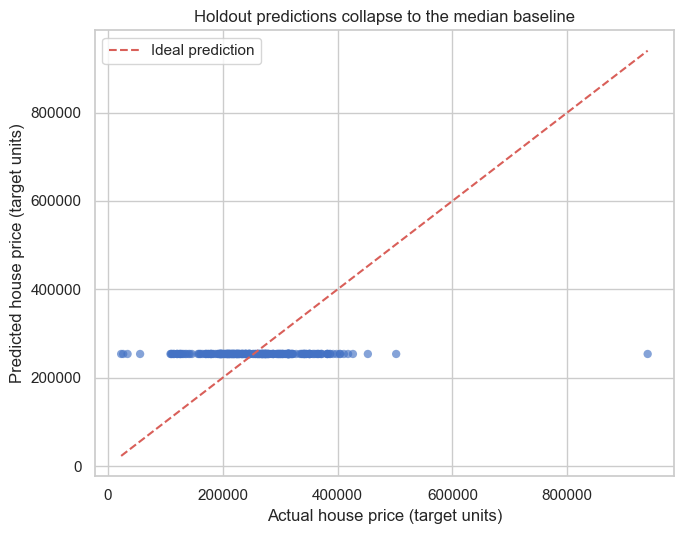

In [9]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(y_test, holdout_predictions, alpha=0.65, color="#4472C4", edgecolor="none")
minimum = min(float(y_test.min()), float(holdout_predictions.min()))
maximum = max(float(y_test.max()), float(holdout_predictions.max()))
ax.plot([minimum, maximum], [minimum, maximum], linestyle="--", color="#D95F59", label="Ideal prediction")
ax.set_title("Holdout predictions collapse to the median baseline")
ax.set_xlabel("Actual house price (target units)")
ax.set_ylabel("Predicted house price (target units)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "holdout_actual_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

### 6. Verify the saved artifact

In [10]:
model_path = DEFAULT_MODEL_DIR / "house_price_pipeline.joblib"
saved_model = joblib.load(model_path)
sample_prediction = saved_model.predict(X.head(1))[0]

print(f"Model artifact: {model_path.relative_to(PROJECT_ROOT)}")
print(f"Example prediction: {sample_prediction:,.2f}")

Model artifact: models\house_price_pipeline.joblib
Example prediction: 253,621.01


## Takeaways

1. The original ANN training issue was real: its unscaled target and architecture produced a severely negative R², and its final prediction call was invalid.
2. The corrected pipeline prevents leakage, handles missing and unseen categories, and evaluates models with regression metrics.
3. Model complexity is not the limiting factor. The current features do not explain the target well enough to beat a constant baseline.
4. The next useful improvement is better data: property location, floor area, bedrooms, bathrooms, property type, condition, and sale date, with documented currency and provenance.
5. Do not deploy this artifact. Treat it as a reproducible baseline and rerun the evaluation after replacing or correcting the dataset.